# 06 — Custos dos erros, ponto de corte e modelo escolhido

Vamos escolher o ponto de corte e o modelo a partir de **custos simulados**, com previsões de validação no treino. Os dois candidatos e seus hiperparâmetros já foram definidos no notebook 05.

**Ordem:** hipóteses de negócio → previsões fora da partição de ajuste (OOF) → escolha do corte e candidato → registro da decisão → avaliação no teste → gravação do pipeline completo e do corte com `joblib`.

Esta etapa ajusta a decisão financeira. Ela não realiza calibração estatística das probabilidades nem demonstra perdas reais de uma instituição financeira.


## 1. Ler o treino e os candidatos congelados

Cada previsão OOF é feita por um pipeline que não foi ajustado com aquele registro. A imputação, o encoding e o estimador são reaprendidos em cada fold. O teste será lido depois da decisão financeira ser registrada.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import display

relativo = Path("data/processed/treino.csv")
raiz = None
for pasta in (Path.cwd(), *Path.cwd().parents):
    if (pasta / relativo).is_file():
        raiz = pasta
        break
if raiz is None:
    raise FileNotFoundError("Gere os conjuntos pelo notebook 02.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.evaluation import gerar_probabilidades_oof, tabela_custos, selecionar_threshold
from src.modeling import criar_modelo, metricas_binarias
from src.preprocessing import COLUNAS_ENTRADA

pasta_resultados = raiz / "docs/resultados"
pasta_figuras = raiz / "docs/figuras"
metadados = json.loads((raiz / "data/processed/separacao.json").read_text())
caminho_selecao = pasta_resultados / "selecao_modelos.json"
hash_selecao = hashlib.sha256(caminho_selecao.read_bytes()).hexdigest()
selecao = json.loads(caminho_selecao.read_text())
ids_finalistas = [r["configuracao"] for r in selecao["finalistas"]]
assert len(ids_finalistas) == 2
caminho_treino = raiz / relativo
assert hashlib.sha256(caminho_treino.read_bytes()).hexdigest() == metadados["sha256_treino"]
treino = pd.read_csv(caminho_treino)
X_train, y_train = treino.drop(columns="loan_status"), treino["loan_status"]
sns.set_theme(style="whitegrid", context="notebook")
print("Candidatos definidos na fase anterior:", ids_finalistas)


Candidatos definidos na fase anterior: ['rf_depth_None', 'rl_C_10']


## 2. Hipóteses de custos e regra de escolha

| Resultado | Interpretação | Custo simulado principal |
| --- | --- | ---: |
| Falso positivo (FP) | Sinalizar como inadimplente quem pagaria; potencial perda de receita e de cliente | 1 UM |
| Falso negativo (FN) | Sinalizar como seguro quem ficaria inadimplente; potencial perda com o crédito concedido | 5 UM |
| Acertos (TN e TP) | Classificação correta | 0 UM |

**UM** significa unidade monetária fictícia. A relação 5:1 é uma hipótese didática, não uma informação da base. Não supomos moeda do empréstimo, recuperação de crédito, juros, prazo ou custo individual por contrato. Se FP custasse 100 e FN 500 na mesma moeda, a decisão seria a mesma, apenas com o custo multiplicado por 100.

**Fórmula:** `custo = FP × custo_fp + FN × custo_fn`. Custos constantes não medem o lucro completo de uma operação. Vamos comparar também proporções FN:FP de 1:1, 2:1, 10:1 e 20:1.

**Grade:** 201 cortes entre 0 e 1, com passo 0,005, incluindo 0,5. A previsão é classe 1 quando `score >= corte`. Por candidato, escolhemos menor custo OOF; em empate, menos FN e, depois, menor corte. Entre candidatos, escolhemos menor custo OOF, depois menos FN e, em empate completo, a logística por simplicidade.

Os custos OOF são resultados de desenvolvimento, usados para selecionar a decisão. Eles não são uma estimativa imparcial de desempenho futuro após essa seleção. O teste reportará a política já fixada, sem orientar nova busca.


In [2]:
CUSTO_FP = 1.0
CUSTO_FN = 5.0
PROPORCOES_FN = [1, 2, 5, 10, 20]
GRADE_THRESHOLDS = np.linspace(0, 1, 201)
print(f"Cenário principal: FP={CUSTO_FP:g} UM; FN={CUSTO_FN:g} UM.")
print(f"Custo OOF de prever sempre seguro: {int(y_train.sum()) * CUSTO_FN:,.0f} UM")
print(f"Custo OOF de prever sempre risco: {int((y_train == 0).sum()) * CUSTO_FP:,.0f} UM")


Cenário principal: FP=1 UM; FN=5 UM.
Custo OOF de prever sempre seguro: 28,355 UM
Custo OOF de prever sempre risco: 20,261 UM


## 3. Gerar as previsões OOF e comparar os cortes

Reutilizamos validação estratificada com três folds e semente 42. Cada finalista faz três ajustes, sempre dentro do treino. Não usamos as previsões do modelo sobre seu próprio ajuste para escolher o corte.

Os resultados agregados da grade ficam em `custos_threshold_oof.csv`. As previsões individuais permanecem em memória.


In [3]:
probabilidades_oof = {}
tabelas_custos = {}
registros = []
grades = []
for identificador in ids_finalistas:
    print("Gerando previsões OOF:", identificador, flush=True)
    probabilidades_oof[identificador] = gerar_probabilidades_oof(identificador, X_train, y_train, n_splits=3)
    tabela = tabela_custos(y_train, probabilidades_oof[identificador], CUSTO_FP, CUSTO_FN, GRADE_THRESHOLDS)
    tabelas_custos[identificador] = tabela
    registros.append({"configuracao": identificador, **selecionar_threshold(tabela)})
    grades.append(tabela.assign(configuracao=identificador))
pd.concat(grades, ignore_index=True).to_csv(pasta_resultados / "custos_threshold_oof.csv", index=False)
escolhas = pd.DataFrame(registros)
escolhas["ordem_simplicidade"] = escolhas["configuracao"].str.startswith("rf_").astype(int)
escolhas = escolhas.sort_values(["custo_total", "fn", "ordem_simplicidade"]).drop(columns="ordem_simplicidade").reset_index(drop=True)
display(escolhas.round(4))


,configuracao,threshold,tn,fp,fn,tp,custo_total,custo_medio,recall,precision,f1
0,rf_depth_None,0.295,17663,2598,931,4740,7253.0,0.2797,0.8358,0.6460,0.7287
1,rl_C_10,0.490,16507,3754,1221,4450,9859.0,0.3802,0.7847,0.5424,0.6414


Gerando previsões OOF: rf_depth_None
Gerando previsões OOF: rl_C_10


## 4. Visualizar o custo conforme o ponto de corte

Um corte menor geralmente sinaliza mais clientes: reduz falsos negativos e pode aumentar falsos positivos. O ponto de menor custo depende da relação de custos assumida e da distribuição dos scores, não apenas da acurácia.


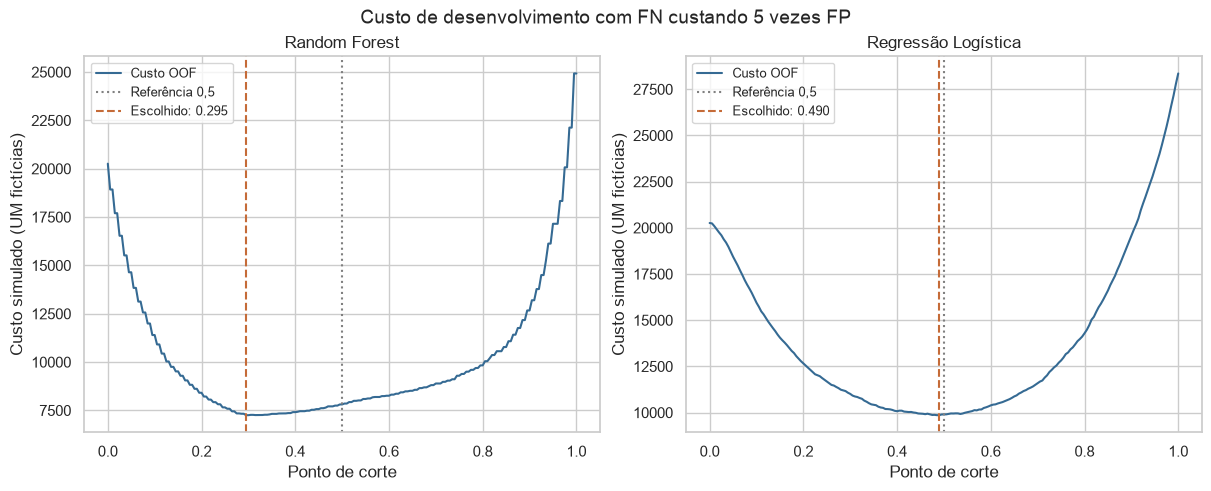

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, identificador in zip(axes, ids_finalistas):
    tabela = tabelas_custos[identificador]
    corte = float(escolhas.loc[escolhas.configuracao == identificador, "threshold"].iloc[0])
    ax.plot(tabela.threshold, tabela.custo_total, color="#356A93", label="Custo OOF")
    ax.axvline(.5, color="gray", linestyle=":", label="Referência 0,5")
    ax.axvline(corte, color="#C56B38", linestyle="--", label=f"Escolhido: {corte:.3f}")
    titulo = "Random Forest" if identificador.startswith("rf_") else "Regressão Logística"
    ax.set(title=titulo, xlabel="Ponto de corte", ylabel="Custo simulado (UM fictícias)")
    ax.legend(fontsize=9)
fig.suptitle("Custo de desenvolvimento com FN custando 5 vezes FP", fontsize=14)
fig.savefig(pasta_figuras / "07_custos_threshold.png", dpi=160)
display(fig)
plt.close(fig)


## 5. Análise de sensibilidade às hipóteses financeiras

Reavaliamos os mesmos scores OOF com diferentes custos de FN. Não refazemos hiperparâmetros nem ajustamos novos modelos com base no teste. A comparação mostra em quais hipóteses a política escolhida faz sentido; nenhum cenário é declarado verdadeiro para uma instituição real.


In [5]:
linhas_sensibilidade = []
for custo_fn in PROPORCOES_FN:
    for identificador in ids_finalistas:
        tabela = tabela_custos(y_train, probabilidades_oof[identificador], 1.0, float(custo_fn), GRADE_THRESHOLDS)
        linhas_sensibilidade.append({"configuracao": identificador, "custo_fp": 1.0,
                                    "custo_fn": custo_fn, **selecionar_threshold(tabela)})
sensibilidade = pd.DataFrame(linhas_sensibilidade)
sensibilidade.to_csv(pasta_resultados / "sensibilidade_custos.csv", index=False)
display(sensibilidade[["custo_fn", "configuracao", "threshold", "fp", "fn", "custo_total", "recall"]].round(4))


,custo_fn,configuracao,threshold,fp,fn,custo_total,recall
0,1,rf_depth_None,0.675,113,1716,1829.0,0.6974
1,1,rl_C_10,0.710,1456,2056,3512.0,0.6375
2,2,rf_depth_None,0.595,229,1606,3441.0,0.7168
3,2,rl_C_10,0.640,2067,1732,5531.0,0.6946
4,5,rf_depth_None,0.295,2598,931,7253.0,0.8358
5,5,rl_C_10,0.490,3754,1221,9859.0,0.7847
6,10,rf_depth_None,0.205,4897,664,11537.0,0.8829
7,10,rl_C_10,0.225,9773,460,14373.0,0.9189
8,20,rf_depth_None,0.105,9552,272,14992.0,0.9520
9,20,rl_C_10,0.110,14922,112,17162.0,0.9803


## 6. Registrar a decisão antes de avaliar o teste

A decisão abaixo usa apenas as previsões OOF e o cenário principal. Registramos o custo e o corte de cada candidato, o vencedor e a identificação do treino. O arquivo será verificado após a avaliação para confirmar que a decisão permaneceu fixa.


In [6]:
vencedor = escolhas.iloc[0].to_dict()
configuracao_campea = vencedor["configuracao"]
threshold_campeao = float(vencedor["threshold"])
decisao = {
    "schema_version": 1,
    "metodo": "Scores OOF com pipeline completo, StratifiedKFold 3 folds e seed 42.",
    "cenario": {"custo_fp": CUSTO_FP, "custo_fn": CUSTO_FN, "unidade": "UM ficticia", "custos_reais": False},
    "grade": {"inicio": 0, "fim": 1, "passo": .005, "pontos": 201},
    "regra": "Classe 1 quando score >= threshold.",
    "criterio_threshold": "Menor custo OOF; desempate por menos FN e menor threshold.",
    "criterio_modelo": "Menor custo OOF; desempate por menos FN e logistica por simplicidade.",
    "configuracao_campea": configuracao_campea,
    "threshold_campeao": threshold_campeao,
    "comparacao_oof": escolhas.to_dict(orient="records"),
    "sha256_treino": metadados["sha256_treino"],
    "sha256_selecao_modelos": hash_selecao,
    "calibracao_probabilistica_realizada": False,
}
caminho_decisao = pasta_resultados / "decisao_financeira.json"
caminho_decisao.write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
hash_decisao = hashlib.sha256(caminho_decisao.read_bytes()).hexdigest()
print("Modelo escolhido por custo OOF:", configuracao_campea)
print("Ponto de corte fixado:", threshold_campeao)


Modelo escolhido por custo OOF: rf_depth_None
Ponto de corte fixado: 0.295


## 7. Avaliar os dois candidatos no teste com decisões fixas

Agora ajustamos cada pipeline no treino completo e avaliamos no teste, usando tanto 0,5 quanto o corte escolhido por OOF. Relatórios completos mostram precision, recall, F1 e support das duas classes, além de accuracy e médias macro/ponderada.

O teste já foi exposto na comparação solicitada pelo roteiro no notebook 05. Mantemos os candidatos e o protocolo, sem usar essa exposição para ajustar o limiar. Os resultados são uma avaliação desta divisão, não uma garantia de perdas futuras.


In [7]:
caminho_teste = raiz / "data/processed/teste.csv"
assert hashlib.sha256(caminho_teste.read_bytes()).hexdigest() == metadados["sha256_teste"]
teste = pd.read_csv(caminho_teste)
X_test, y_test = teste.drop(columns="loan_status"), teste["loan_status"]
pipelines = {}
probabilidades_teste = {}
linhas_teste = []
relatorios = {}
for identificador in ids_finalistas:
    pipeline = criar_modelo(identificador).fit(X_train, y_train)
    pipelines[identificador] = pipeline
    indice_positivo = list(pipeline.classes_).index(1)
    scores = pipeline.predict_proba(X_test)[:, indice_positivo]
    probabilidades_teste[identificador] = scores
    corte_oof = float(escolhas.loc[escolhas.configuracao == identificador, "threshold"].iloc[0])
    relatorios[identificador] = {}
    for politica, corte in [("padrao_0.5", .5), ("ajustado_oof", corte_oof)]:
        custos = tabela_custos(y_test, scores, CUSTO_FP, CUSTO_FN, [corte]).iloc[0].to_dict()
        for campo in ["tn", "fp", "fn", "tp"]:
            custos[campo] = int(custos[campo])
        linhas_teste.append({"configuracao": identificador, "politica": politica, **custos,
                            "roc_auc": metricas_binarias(y_test, scores, corte)["roc_auc"]})
        classes = (scores >= corte).astype(int)
        relatorios[identificador][politica] = classification_report(
            y_test, classes, labels=[0, 1], target_names=["adimplente", "inadimplente"],
            output_dict=True, zero_division=0,
        )
        print(f"\n{identificador} — {politica}, corte={corte:.3f}")
        print(classification_report(y_test, classes, labels=[0, 1],
                                    target_names=["adimplente", "inadimplente"], digits=4, zero_division=0))
avaliacao_teste = pd.DataFrame(linhas_teste)
avaliacao_teste.to_csv(pasta_resultados / "avaliacao_financeira_teste.csv", index=False)
(pasta_resultados / "relatorios_classificacao.json").write_text(json.dumps(relatorios, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(avaliacao_teste.round(4))
assert hashlib.sha256(caminho_decisao.read_bytes()).hexdigest() == hash_decisao


,configuracao,politica,threshold,tn,fp,fn,tp,custo_total,custo_medio,recall,precision,f1,roc_auc
0,rf_depth_None,padrao_0.5,0.500,4948,118,351,1067,1873.0,0.2889,0.7525,0.9004,0.8198,0.9299
1,rf_depth_None,ajustado_oof,0.295,4476,590,250,1168,1840.0,0.2838,0.8237,0.6644,0.7355,0.9299
2,rl_C_10,padrao_0.5,0.500,4193,873,320,1098,2473.0,0.3814,0.7743,0.5571,0.6480,0.8720
3,rl_C_10,ajustado_oof,0.490,4161,905,315,1103,2480.0,0.3825,0.7779,0.5493,0.6439,0.8720



rf_depth_None — padrao_0.5, corte=0.500
              precision    recall  f1-score   support

  adimplente     0.9338    0.9767    0.9548      5066
inadimplente     0.9004    0.7525    0.8198      1418

    accuracy                         0.9277      6484
   macro avg     0.9171    0.8646    0.8873      6484
weighted avg     0.9265    0.9277    0.9252      6484


rf_depth_None — ajustado_oof, corte=0.295
              precision    recall  f1-score   support

  adimplente     0.9471    0.8835    0.9142      5066
inadimplente     0.6644    0.8237    0.7355      1418

    accuracy                         0.8705      6484
   macro avg     0.8057    0.8536    0.8249      6484
weighted avg     0.8853    0.8705    0.8751      6484


rl_C_10 — padrao_0.5, corte=0.500
              precision    recall  f1-score   support

  adimplente     0.9291    0.8277    0.8755      5066
inadimplente     0.5571    0.7743    0.6480      1418

    accuracy                         0.8160      6484
   macro 

## 8. Matrizes de confusão: referência e corte ajustado

Linhas representam a classe real e colunas, a classe prevista. No quadrante superior direito estão os falsos positivos; no inferior esquerdo, os falsos negativos. A escala de cor é compartilhada entre os quatro painéis.


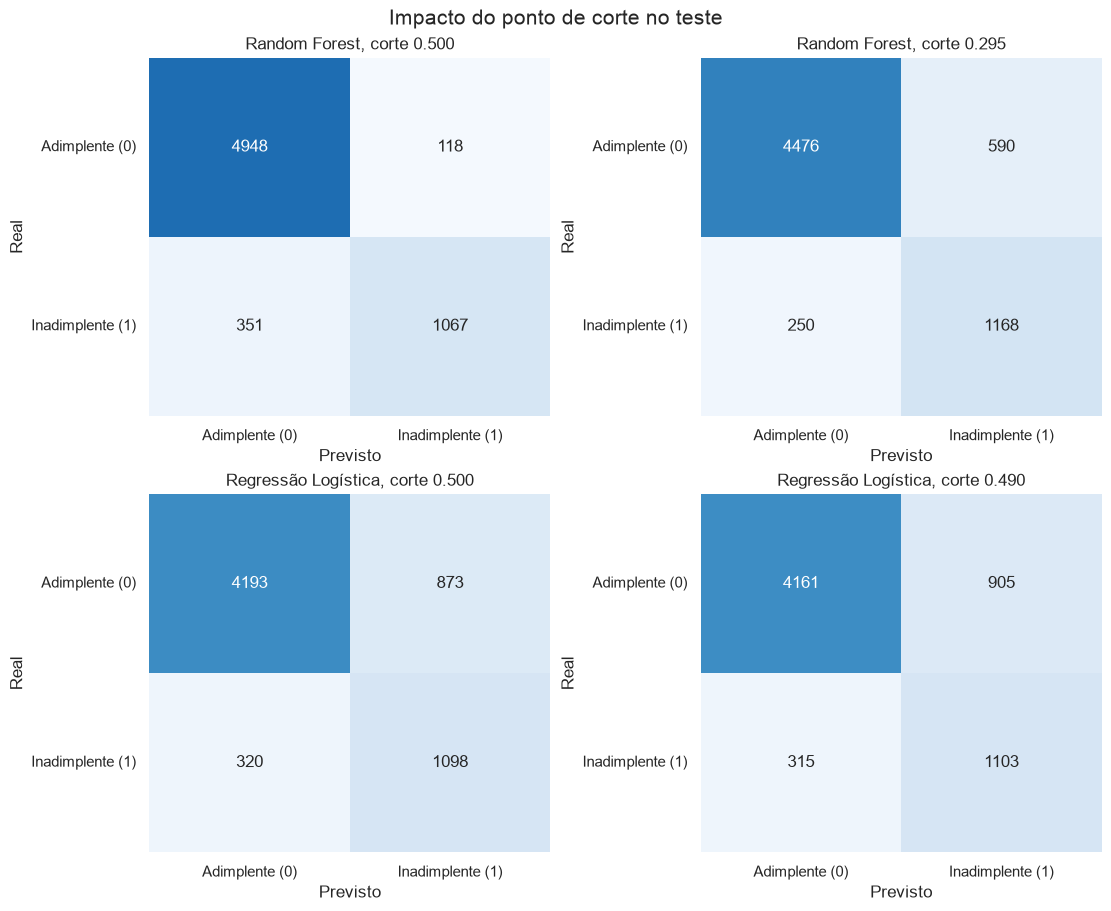

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
for linha, identificador in enumerate(ids_finalistas):
    scores = probabilidades_teste[identificador]
    corte_oof = float(escolhas.loc[escolhas.configuracao == identificador, "threshold"].iloc[0])
    nome = "Random Forest" if identificador.startswith("rf_") else "Regressão Logística"
    for coluna, corte in enumerate([.5, corte_oof]):
        matriz = confusion_matrix(y_test, (scores >= corte).astype(int), labels=[0, 1])
        ax = axes[linha, coluna]
        sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", vmin=0, vmax=len(y_test), cbar=False,
                    xticklabels=["Adimplente (0)", "Inadimplente (1)"],
                    yticklabels=["Adimplente (0)", "Inadimplente (1)"], ax=ax)
        ax.set(title=f"{nome}, corte {corte:.3f}", xlabel="Previsto", ylabel="Real")
        ax.tick_params(axis="y", labelrotation=0)
fig.suptitle("Impacto do ponto de corte no teste", fontsize=15)
fig.savefig(pasta_figuras / "08_matrizes_confusao.png", dpi=160)
display(fig)
plt.close(fig)


## 9. Salvar o pipeline campeão e o ponto de corte

O artefato contém o pipeline já ajustado no treino completo, o corte escolhido por OOF, a configuração e as hipóteses de custo. A API deverá carregar esse conjunto e aplicar o corte salvo; usar apenas `pipeline.predict()` voltaria à decisão padrão do estimador.

O arquivo `models/metadata_credito.json` permite revisar configuração, versões, campos de entrada e identificação do artefato. Conferimos o resultado após recarregar o arquivo com `joblib`.


In [9]:
pasta_modelos = raiz / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)
artefato = {
    "schema_version": 1,
    "pipeline": pipelines[configuracao_campea],
    "threshold": threshold_campeao,
    "configuracao": configuracao_campea,
    "campos_entrada": COLUNAS_ENTRADA,
    "custos": decisao["cenario"],
    "sha256_decisao": hash_decisao,
}
caminho_artefato = pasta_modelos / "modelo_credito.joblib"
joblib.dump(artefato, caminho_artefato, compress=3)
restaurado = joblib.load(caminho_artefato)
amostra = X_test.loc[:, COLUNAS_ENTRADA].head(20)
antes = artefato["pipeline"].predict_proba(amostra)
depois = restaurado["pipeline"].predict_proba(amostra)
np.testing.assert_allclose(antes, depois, rtol=0, atol=0)
assert restaurado["threshold"] == decisao["threshold_campeao"]
np.testing.assert_array_equal(antes[:, 1] >= threshold_campeao, depois[:, 1] >= restaurado["threshold"])

metadata_artefato = {
    "schema_version": 1,
    "arquivo": "modelo_credito.joblib",
    "sha256_artefato": hashlib.sha256(caminho_artefato.read_bytes()).hexdigest(),
    "configuracao": configuracao_campea,
    "threshold": threshold_campeao,
    "regra": "Classe 1 quando predict_proba da classe 1 >= threshold.",
    "classes": artefato["pipeline"].classes_.tolist(),
    "campos_entrada": COLUNAS_ENTRADA,
    "registros_treino": len(X_train),
    "sha256_treino": metadados["sha256_treino"],
    "sha256_decisao": hash_decisao,
    "custos": decisao["cenario"],
    "versoes": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
}
(pasta_modelos / "metadata_credito.json").write_text(json.dumps(metadata_artefato, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Pipeline e threshold gravados e recarregados sem alteração nas previsões.")
print(f"Artefato: models/modelo_credito.joblib ({caminho_artefato.stat().st_size:,} bytes)")


Pipeline e threshold gravados e recarregados sem alteração nas previsões.
Artefato: models/modelo_credito.joblib (7,979,243 bytes)


## 10. Veredito de negócio e limites

**Escolha por validação no treino:** no cenário fictício FP=1 UM e FN=5 UM, a Random Forest (`rf_depth_None`) apresenta custo OOF de **7.253 UM**, com corte **0,295**, contra **9.859 UM** da logística com corte **0,490**. O critério de custo foi fixado antes da leitura do teste. Na floresta, o custo OOF cai de 7.808 UM no corte 0,5 para 7.253 UM no corte ajustado (7,11%); isso é resultado de desenvolvimento usado na escolha, não ganho futuro garantido.

**Efeito no teste:** a floresta passa de 351 para 250 falsos negativos e de 118 para 590 falsos positivos. O recall dos inadimplentes sobe de **75,25% para 82,37%**, enquanto a precisão cai de **90,04% para 66,44%** e o F1 de **0,8198 para 0,7355**. A troca é coerente com a hipótese de que deixar passar um inadimplente custa mais que sinalizar um bom pagador.

**Resultado financeiro simulado:** no teste, o custo cai de **1.873 para 1.840 UM**, redução de **33 UM (1,76%)**. São 101 FN evitados, com benefício simulado de 505 UM, ao custo de 472 FP adicionais. Esse ganho é pequeno e específico da divisão; não demonstramos significância estatística nem lucro real. A logística passa de 2.473 para 2.480 UM no teste, apesar de melhorar ligeiramente no OOF. Isso mostra que otimizar o corte no desenvolvimento não garante melhora no teste; mantemos a decisão originalmente fixada.

**Sensibilidade:** a floresta tem menor custo OOF que a logística nas cinco relações de custo avaliadas. Seu corte muda de 0,675 quando FN e FP têm o mesmo custo para 0,105 quando FN custa vinte vezes FP. Portanto, **0,295 não é um corte universal**. As hipóteses precisam ser substituídas por custos operacionais reais antes de interpretar o resultado como uma decisão de negócio real.

**Limitações:** a floresta mantém o sinal de overfitting identificado na etapa anterior. A escolha considera seu desempenho fora do ajuste, mas não elimina esse risco. Os scores não passaram por calibração probabilística, e o corte 0,295 não comprova risco real de 29,5%. A hipótese de custos constantes ignora valores e recuperação dos empréstimos, receita, prazo e capacidade de revisão da operação. A disponibilidade temporal dos atributos e as definições da base também precisam de confirmação.

**Artefato escolhido para a API do projeto:** `models/modelo_credito.joblib`, com pipeline completo ajustado nos 25.932 registros de treino, corte 0,295, configuração, campos de entrada e cenário de custos. O arquivo foi recarregado e as previsões permaneceram idênticas. A integração com FastAPI será a próxima etapa.



In [10]:
assert hashlib.sha256(caminho_treino.read_bytes()).hexdigest() == metadados["sha256_treino"]
assert hashlib.sha256(caminho_teste.read_bytes()).hexdigest() == metadados["sha256_teste"]
assert hashlib.sha256(caminho_selecao.read_bytes()).hexdigest() == hash_selecao
assert hashlib.sha256(caminho_decisao.read_bytes()).hexdigest() == hash_decisao
print("Dados preservados; candidatos e decisão não alterados após a avaliação de teste.")
print("Próxima etapa: carregar o artefato em uma API FastAPI com GET /health e POST /predict.")


Dados preservados; candidatos e decisão não alterados após a avaliação de teste.
Próxima etapa: carregar o artefato em uma API FastAPI com GET /health e POST /predict.
